# DWD-Wetterdaten für Berlin, 2020 bis aktuell

Dieses Notebook lädt tägliche DWD-Daten der Station **Berlin-Dahlem (FU), Stations-ID 00403**, speichert sie als CSV und prüft die Messwertverfügbarkeit. Anschließend erstellt es mit einem kleinen neuronalen Netz eine Ein-Tages-Prognose der Tagesmitteltemperatur aus den fünf vorherigen Tageswerten und dem Jahrestag.

Die Archivprüfung am 02.11.2026 fand Daten vom **01.01.2020 bis 01.11.2026**. Einzelne Tage oder Messwerte fehlen; sie bleiben in der CSV leer statt durch erfundene Werte ersetzt zu werden. Die Prognose ist ein Lernbeispiel, keine professionelle Wettervorhersage.

**CSV-Datei:** `dwd_berlin_dahlem_tagesdaten_2020_bis_aktuell.csv`

## Datenquelle und Variablen

Für die tägliche Klimavariable nutzt der DWD diese Spalten und Einheiten:

- `TNK`: Tagesminimum der Lufttemperatur in °C
- `TXK`: Tagesmaximum der Lufttemperatur in °C
- `TMK`: Tagesmitteltemperatur in °C
- `RSK`: tägliche Niederschlagshöhe in mm
- `SDK`: tägliche Sonnenscheindauer in Stunden

Die historischen und aktuellen Archive überlappen teilweise. Beim Zusammenführen erhält ein Eintrag aus dem aktuellen Archiv Vorrang.

In [1]:
import io
import zipfile
from urllib.request import urlopen

import pandas as pd

DWD_BASIS = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/"
DWD_ARCHIVE = [
    "historical/tageswerte_KL_00403_19500101_20251231_hist.zip",
    "recent/tageswerte_KL_00403_akt.zip",
]
CSV_DATEI = "dwd_berlin_dahlem_tagesdaten_2020_bis_aktuell.csv"

archiv_tabellen = []
for archiv_pfad in DWD_ARCHIVE:
    with urlopen(DWD_BASIS + archiv_pfad, timeout=60) as antwort:
        zip_daten = antwort.read()

    with zipfile.ZipFile(io.BytesIO(zip_daten)) as archiv:
        produktdatei = next(
            name
            for name in archiv.namelist()
            if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
        )
        with archiv.open(produktdatei) as csv_daten:
            tabelle = pd.read_csv(
                csv_daten,
                sep=";",
                skipinitialspace=True,
                na_values=[-999, "-999"],
                encoding="cp1252",
                low_memory=False,
            )
    tabelle.columns = tabelle.columns.str.strip()
    archiv_tabellen.append(tabelle)

# Bei überlappenden Tagen gewinnt das aktuelle Archiv.
dwd_roh = pd.concat(archiv_tabellen, ignore_index=True)
dwd_roh["MESS_DATUM"] = pd.to_datetime(
    dwd_roh["MESS_DATUM"].astype("Int64").astype(str),
    format="%Y%m%d",
)
dwd_roh = dwd_roh.drop_duplicates(subset="MESS_DATUM", keep="last")

letzter_dwd_tag = min(pd.Timestamp.today().normalize(), dwd_roh["MESS_DATUM"].max())
start = pd.Timestamp("2020-01-01")
spalten = {
    "MESS_DATUM": "datum",
    "TNK": "temp_min_c",
    "TXK": "temp_max_c",
    "TMK": "temp_avg_c",
    "RSK": "niederschlagsmenge_mm",
    "SDK": "sonnenstunden_h",
}

dwd_csv = dwd_roh.loc[
    dwd_roh["MESS_DATUM"].between(start, letzter_dwd_tag),
    list(spalten),
].rename(columns=spalten)

# Fehlende Kalendertage bleiben als Zeilen mit leeren Messwerten sichtbar.
dwd_csv = (
    dwd_csv.set_index("datum")
    .reindex(pd.date_range(start, letzter_dwd_tag, freq="D", name="datum"))
    .reset_index()
)
dwd_csv.to_csv(CSV_DATEI, index=False, date_format="%Y-%m-%d", na_rep="")

print(f"Gespeichert: {CSV_DATEI}")
print(f"Station: Berlin-Dahlem (FU), 00403")
print(f"Zeitraum: {dwd_csv['datum'].min().date()} bis {dwd_csv['datum'].max().date()}")
print(f"Kalendertage in CSV: {len(dwd_csv)}")
print("Gültige Werte je Variable:\n", dwd_csv.notna().sum())
dwd_csv.head()

Gespeichert: dwd_berlin_dahlem_tagesdaten_2020_bis_aktuell.csv
Station: Berlin-Dahlem (FU), 00403
Zeitraum: 2020-01-01 bis 2026-11-01
Kalendertage in CSV: 2497
Gültige Werte je Variable:
 datum                    2497
temp_min_c               2481
temp_max_c               2481
temp_avg_c               2481
niederschlagsmenge_mm    2482
sonnenstunden_h          2481
dtype: int64


,datum,temp_min_c,temp_max_c,temp_avg_c,niederschlagsmenge_mm,sonnenstunden_h
0,2020-01-01,-2.8,5.0,1.8,0.0,2.9
1,2020-01-02,-4.1,6.2,-0.3,0.0,7.5
2,2020-01-03,0.8,6.9,4.3,4.4,0.0
3,2020-01-04,1.7,5.6,4.1,3.0,0.0
4,2020-01-05,-1.4,3.6,1.4,0.0,2.1


## CSV-Datei und Verfügbarkeit prüfen

Diese Zelle liest die gespeicherte CSV erneut ein, prüft die erwarteten Spalten und zeigt gültige sowie fehlende Tageswerte. Die folgenden Notebook-Abschnitte verwenden die geprüften Daten anschließend für eine Prognose der Tagesmitteltemperatur.

In [2]:
daten = pd.read_csv(CSV_DATEI, parse_dates=["datum"])
benoetigte_spalten = [
    "datum",
    "temp_min_c",
    "temp_max_c",
    "temp_avg_c",
    "niederschlagsmenge_mm",
    "sonnenstunden_h",
]
fehlende_spalten = set(benoetigte_spalten) - set(daten.columns)
assert not fehlende_spalten, f"Fehlende Spalten: {fehlende_spalten}"
assert daten["datum"].is_monotonic_increasing
assert daten["datum"].is_unique
assert len(daten) == (daten["datum"].max() - daten["datum"].min()).days + 1

print(f"Station: Berlin-Dahlem (FU), 00403")
print(f"CSV-Zeitraum: {daten['datum'].min().date()} bis {daten['datum'].max().date()}")
print(f"Kalendertage: {len(daten)}")

verfuegbarkeit = pd.DataFrame(
    {
        "gueltige_tage": daten[benoetigte_spalten[1:]].notna().sum(),
        "fehlende_tage": daten[benoetigte_spalten[1:]].isna().sum(),
        "verfuegbar_prozent": (
            daten[benoetigte_spalten[1:]].notna().mean() * 100
        ).round(2),
    }
)
verfuegbarkeit

Station: Berlin-Dahlem (FU), 00403
CSV-Zeitraum: 2020-01-01 bis 2026-11-01
Kalendertage: 2497


,gueltige_tage,fehlende_tage,verfuegbar_prozent
temp_min_c,2481,16,99.36
temp_max_c,2481,16,99.36
temp_avg_c,2481,16,99.36
niederschlagsmenge_mm,2482,15,99.40
sonnenstunden_h,2481,16,99.36


## Tagesmitteltemperatur nach Jahren vergleichen

Die Linien legen die Tagesmitteltemperaturen (`temp_avg_c`) auf einer gemeinsamen Kalenderachse übereinander. Jede Jahreskurve erhält eine eigene Farbe. Das laufende Jahr enthält nur Werte bis zum letzten DWD-Messtag und ist in der Legende als unvollständig gekennzeichnet.

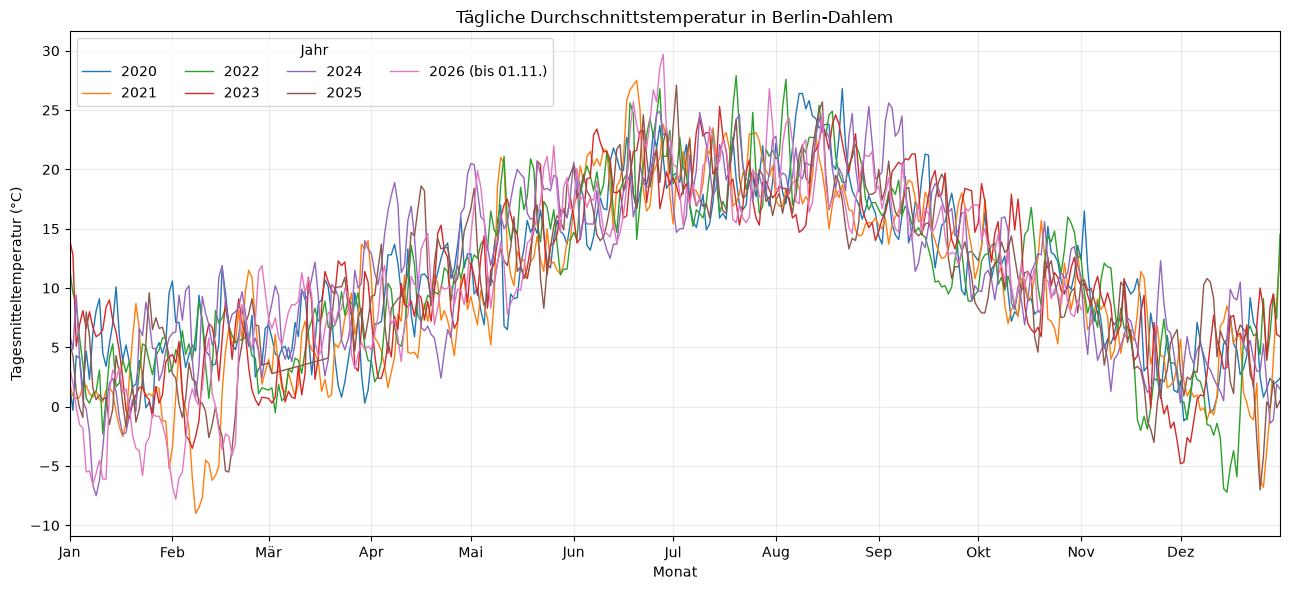

In [3]:
import matplotlib.pyplot as plt

plot_daten = daten.dropna(subset=["temp_avg_c"]).copy()
plot_daten["vergleichsdatum"] = pd.to_datetime(
    "2000-" + plot_daten["datum"].dt.strftime("%m-%d")
)

fig, ax = plt.subplots(figsize=(13, 6))
farben = plt.get_cmap("tab10")

for index, (jahr, jahresdaten) in enumerate(
    plot_daten.groupby(plot_daten["datum"].dt.year)
):
    letzter_tag = jahresdaten["datum"].max()
    beschriftung = (
        f"{jahr} (bis {letzter_tag:%d.%m.})"
        if letzter_tag < pd.Timestamp(year=int(jahr), month=12, day=31)
        else str(jahr)
    )
    ax.plot(
        jahresdaten["vergleichsdatum"],
        jahresdaten["temp_avg_c"],
        color=farben(index % 10),
        linewidth=1,
        label=beschriftung,
    )

ax.set_title("Tägliche Durchschnittstemperatur in Berlin-Dahlem")
ax.set_xlabel("Monat")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.set_xticks(pd.date_range("2000-01-01", "2000-12-01", freq="MS"))
ax.set_xticklabels(["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))
ax.grid(True, alpha=0.25)
ax.legend(title="Jahr", ncols=4)
fig.tight_layout()
plt.show()

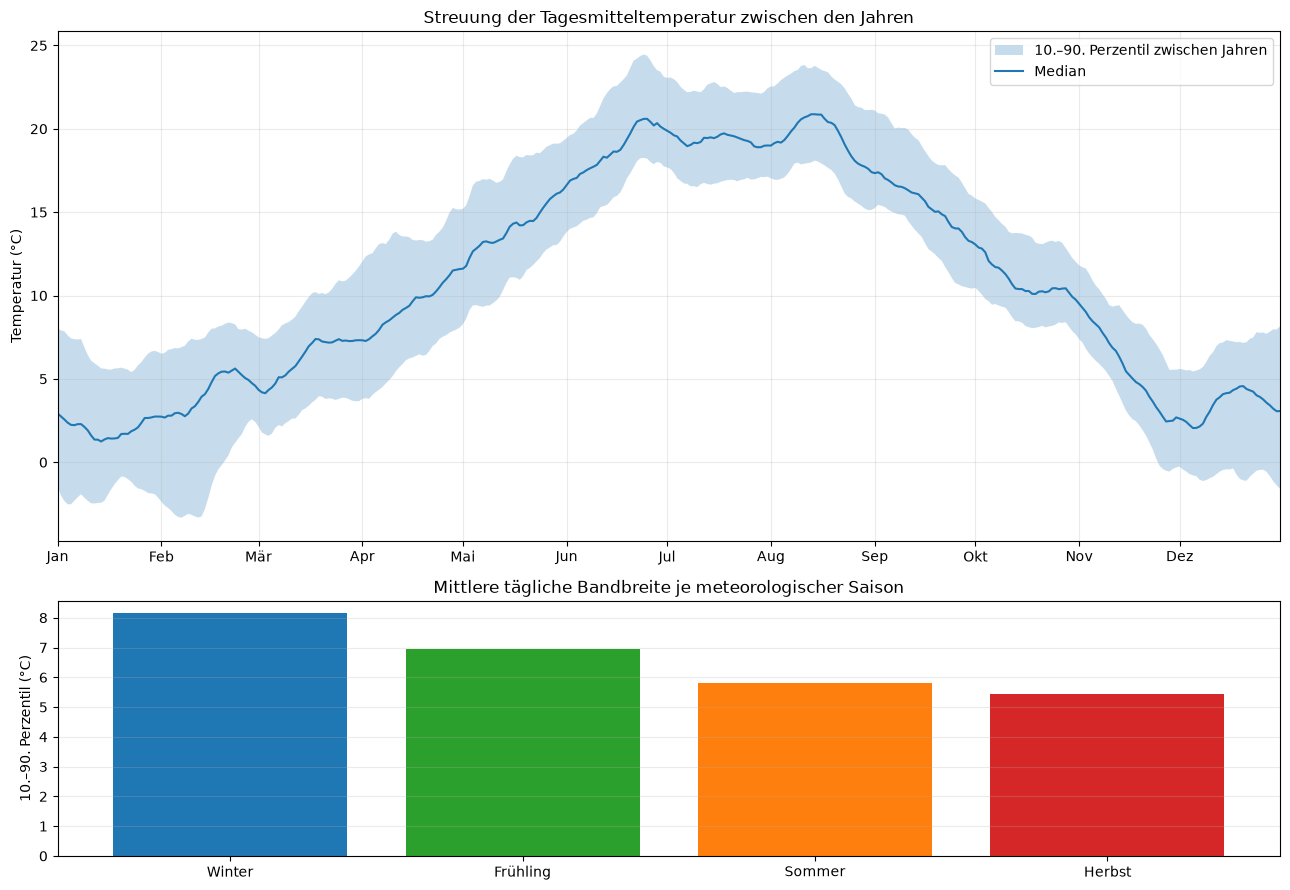

Mittlere tägliche Bandbreite je Saison (°C):


,Bandbreite (°C)
saison,
Winter,8.15
Frühling,6.95
Sommer,5.80
Herbst,5.43


Die Winter-Bandbreite ist im Mittel größer als die Sommer-Bandbreite (Differenz: +2.35 °C).


In [4]:
# Streuung der Tagesmitteltemperatur zwischen den Jahren je Kalendertag
tagesstreuung = (
    plot_daten.groupby(plot_daten["datum"].dt.strftime("%m-%d"))["temp_avg_c"]
    .agg(
        median="median",
        unten=lambda werte: werte.quantile(0.10),
        oben=lambda werte: werte.quantile(0.90),
        anzahl="count",
    )
)
tagesstreuung.index = pd.to_datetime("2000-" + tagesstreuung.index)
tagesstreuung["bandbreite"] = tagesstreuung["oben"] - tagesstreuung["unten"]

# Glättung nur für die Darstellung; Saisonwerte beruhen auf den ungekürzten Daten.
geglattet = tagesstreuung[["median", "unten", "oben"]].rolling(
    window=15, center=True, min_periods=5
).mean()

def meteorologische_saison(monat):
    if monat in (12, 1, 2):
        return "Winter"
    if monat in (3, 4, 5):
        return "Frühling"
    if monat in (6, 7, 8):
        return "Sommer"
    return "Herbst"

tagesstreuung["saison"] = [
    meteorologische_saison(datum.month) for datum in tagesstreuung.index
]
saison_reihenfolge = ["Winter", "Frühling", "Sommer", "Herbst"]
saison_breite = (
    tagesstreuung.groupby("saison")["bandbreite"]
    .mean()
    .reindex(saison_reihenfolge)
)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(13, 9), gridspec_kw={"height_ratios": [2, 1]}
)

ax1.fill_between(
    geglattet.index,
    geglattet["unten"],
    geglattet["oben"],
    alpha=0.25,
    label="10.–90. Perzentil zwischen Jahren",
)
ax1.plot(geglattet.index, geglattet["median"], color="C0", label="Median")
ax1.set_title("Streuung der Tagesmitteltemperatur zwischen den Jahren")
ax1.set_ylabel("Temperatur (°C)")
ax1.set_xticks(pd.date_range("2000-01-01", "2000-12-01", freq="MS"))
ax1.set_xticklabels(
    ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
)
ax1.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2000-12-31"))
ax1.grid(True, alpha=0.25)
ax1.legend()

ax2.bar(saison_breite.index, saison_breite.values, color=["C0", "C2", "C1", "C3"])
ax2.set_title("Mittlere tägliche Bandbreite je meteorologischer Saison")
ax2.set_ylabel("10.–90. Perzentil (°C)")
ax2.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

print("Mittlere tägliche Bandbreite je Saison (°C):")
display(saison_breite.round(2).rename("Bandbreite (°C)").to_frame())

if pd.notna(saison_breite["Winter"]) and pd.notna(saison_breite["Sommer"]):
    differenz = saison_breite["Winter"] - saison_breite["Sommer"]
    aussage = "größer" if differenz > 0 else "nicht größer"
    print(
        f"Die Winter-Bandbreite ist im Mittel {aussage} als die Sommer-Bandbreite "
        f"(Differenz: {differenz:+.2f} °C)."
    )

In [ ]:
## Typische Arbeitsschritte einer Datenanalyse

1. **Fragestellung festlegen**  
    Welche Frage soll mit den Daten beantwortet werden?

2. **Daten beschaffen und verstehen**  
    Datenquelle, Zeitraum, Variablen und Einheiten prüfen.

3. **Daten bereinigen und vorbereiten**  
    Datentypen kontrollieren, fehlende Werte und Duplikate erkennen und Daten bei Bedarf umformen. Fehlende Messwerte nicht ohne Begründung ersetzen.

4. **Datenqualität prüfen**  
    Wertebereiche, Vollständigkeit und zeitliche Reihenfolge kontrollieren.

5. **Daten explorieren**  
    Kennzahlen und Verteilungen untersuchen sowie mögliche Muster oder Auffälligkeiten suchen.

6. **Daten analysieren und visualisieren**  
    Geeignete Auswertungen und Diagramme passend zur Fragestellung erstellen.

7. **Ergebnisse interpretieren**  
    Beobachtungen im Kontext der Daten einordnen und Unsicherheiten oder Einschränkungen benennen.

8. **Ergebnisse dokumentieren und kommunizieren**  
    Vorgehen, Annahmen und Schlussfolgerungen nachvollziehbar festhalten.

In [ ]:
# Datenprognose mit KI


# Prognose der Tagesmitteltemperatur

Wir bauen ein einfaches neuronales Netz für eine **Ein-Tages-Prognose**. Für jeden Tag soll die mittlere Temperatur aus den fünf vorherigen Tagesmitteltemperaturen und dem Kalendertag des Zieltags vorhergesagt werden.

## Schritte

1. **Trainingsbeispiele aufbauen:** Eine Zeile steht für einen vorherzusagenden Tag. Die Eingaben sind `temp_avg_vortag_1` bis `temp_avg_vortag_5` sowie `tag_im_jahr`; das Ziel ist `temp_avg_c` des Tages. Fehlende Messwerte werden nicht geschätzt, sondern die betroffenen Trainingszeilen ausgelassen.
2. **Jahreszahl vereinheitlichen:** Das Modell erhält einen Jahrestag von 1 bis 365. Der 29. Februar wird als Zieltag ausgelassen; nach dem Schalttag wird die Tagesnummer um eins korrigiert.
3. **Zeitlich testen:** Daten bis einschließlich 2024 dienen zum Training, das vollständige Jahr 2025 ausschließlich zum Test. So wird nicht zufällig zwischen Vergangenheit und Zukunft gemischt.
4. **KI-Modell trainieren:** Ein kleines mehrschichtiges Perzeptron (`MLPRegressor`) lernt die Beziehung zwischen Eingaben und Tagesmitteltemperatur. Ein `StandardScaler` bringt Temperaturen und Jahrestag auf vergleichbare Skalen.
5. **Genauigkeit bewerten:** MAE und RMSE messen den typischen Vorhersagefehler in °C; $R^2$ beschreibt, wie viel der Schwankung das Modell erklärt. Zusätzlich vergleichen wir mit einer einfachen Persistenz-Baseline, die für morgen den Wert von heute vorhersagt.
6. **Nächsten Tag prognostizieren:** Nach dem Test wird das Modell mit allen verfügbaren Trainingsbeispielen neu trainiert und schätzt den Tag nach dem letzten Messdatum.

Das ist ein Lernmodell, keine professionelle Wettervorhersage: Es verwendet nur Temperaturverlauf und Jahreszeit, keine Luftdruck-, Wind- oder Niederschlagsdaten. Falls `scikit-learn` in einer anderen Umgebung fehlt, installiere es dort mit `%pip install scikit-learn`.

In [4]:
import numpy as np

zielspalte = "temp_avg_c"
feature_spalten = [
    *(f"temp_avg_vortag_{lag}" for lag in range(1, 6)),
    "tag_im_jahr",
]

modell_daten = daten[["datum", zielspalte]].copy()
for lag in range(1, 6):
    modell_daten[f"temp_avg_vortag_{lag}"] = daten[zielspalte].shift(lag)

# Schalttage auslassen und spätere Tage auf den 365-Tage-Kalender abbilden.
leap_year = modell_daten["datum"].dt.is_leap_year
nach_februar = leap_year & modell_daten["datum"].dt.month.gt(2)
schalttag = modell_daten["datum"].dt.strftime("%m-%d").eq("02-29")
modell_daten["tag_im_jahr"] = modell_daten["datum"].dt.day_of_year.astype("Int64")
modell_daten.loc[nach_februar, "tag_im_jahr"] -= 1
modell_daten.loc[schalttag, "tag_im_jahr"] = pd.NA

modell_daten = modell_daten.dropna(
    subset=[zielspalte, *feature_spalten]
).copy()
modell_daten["tag_im_jahr"] = modell_daten["tag_im_jahr"].astype(int)

assert modell_daten["tag_im_jahr"].between(1, 365).all()
print(f"Trainingsbeispiele nach Entfernen unvollständiger Zeilen: {len(modell_daten)}")
print(f"Eingabespalten: {feature_spalten}")
print(f"Zielspalte: {zielspalte}")
modell_daten[["datum", *feature_spalten, zielspalte]].head(8)

Trainingsbeispiele nach Entfernen unvollständiger Zeilen: 2469
Eingabespalten: ['temp_avg_vortag_1', 'temp_avg_vortag_2', 'temp_avg_vortag_3', 'temp_avg_vortag_4', 'temp_avg_vortag_5', 'tag_im_jahr']
Zielspalte: temp_avg_c


,datum,temp_avg_vortag_1,temp_avg_vortag_2,temp_avg_vortag_3,temp_avg_vortag_4,temp_avg_vortag_5,tag_im_jahr,temp_avg_c
5,2020-01-06,1.4,4.1,4.3,-0.3,1.8,6,4.7
6,2020-01-07,4.7,1.4,4.1,4.3,-0.3,7,2.3
7,2020-01-08,2.3,4.7,1.4,4.1,4.3,8,6.2
8,2020-01-09,6.2,2.3,4.7,1.4,4.1,9,8.1
9,2020-01-10,8.1,6.2,2.3,4.7,1.4,10,9.1
10,2020-01-11,9.1,8.1,6.2,2.3,4.7,11,4.5
11,2020-01-12,4.5,9.1,8.1,6.2,2.3,12,3.4
12,2020-01-13,3.4,4.5,9.1,8.1,6.2,13,5.3


## Schritt 2: Training und Test zeitlich trennen

Wir trainieren mit Beispielen vor dem 1. Januar 2025 und testen ausschließlich auf dem Kalenderjahr 2025. Ein zufälliger Split wäre für Zeitreihen ungeeignet, weil dabei spätere Tage im Training landen könnten, obwohl wir frühere Tage vorhersagen wollen. 2026 bleibt zunächst außen vor und kann nach der Bewertung für die abschließende Prognose genutzt werden.

In [5]:
test_start = pd.Timestamp("2025-01-01")
test_ende = pd.Timestamp("2026-01-01")
train_daten = modell_daten.loc[modell_daten["datum"] < test_start].copy()
test_daten = modell_daten.loc[
    modell_daten["datum"].ge(test_start)
    & modell_daten["datum"].lt(test_ende)
].copy()

assert not train_daten.empty
assert not test_daten.empty
assert train_daten["datum"].max() < test_daten["datum"].min()

X_train = train_daten[feature_spalten]
y_train = train_daten[zielspalte]
X_test = test_daten[feature_spalten]
y_test = test_daten[zielspalte]

print(f"Trainingszeitraum: {train_daten['datum'].min().date()} bis {train_daten['datum'].max().date()}")
print(f"Trainingsbeispiele: {len(train_daten)}")
print(f"Testzeitraum: {test_daten['datum'].min().date()} bis {test_daten['datum'].max().date()}")
print(f"Testbeispiele: {len(test_daten)}")

Trainingszeitraum: 2020-01-06 bis 2024-12-31
Trainingsbeispiele: 1820
Testzeitraum: 2025-01-01 bis 2025-12-31
Testbeispiele: 344


## Schritt 3: Neuronales Netz trainieren

`MLPRegressor` ist ein kleines künstliches neuronales Netz für Zahlenvorhersagen. Die zwei verborgenen Schichten mit 32 und 16 Neuronen können Zusammenhänge zwischen den fünf Vortagswerten, der Jahreszeit und der Temperatur lernen. Der `StandardScaler` standardisiert die Eingaben vor dem Training; dadurch kann das Optimierungsverfahren die unterschiedlich skalierten Temperaturen und Jahrestage besser verarbeiten. Ein fester Zufallsstartwert macht das Beispiel reproduzierbar.

In [6]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

temperatur_modell = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.01,
        max_iter=1500,
        random_state=42,
    ),
)
temperatur_modell.fit(X_train, y_train)

print("Modelltraining abgeschlossen.")
print(f"Trainingsiterationen: {temperatur_modell[-1].n_iter_}")

Modelltraining abgeschlossen.
Trainingsiterationen: 227


## Schritt 4: Testgenauigkeit messen

Das Modell sagt jetzt die Temperaturen im zuvor zurückgehaltenen Jahr 2025 voraus. Wir vergleichen die Prognosen mit den tatsächlichen DWD-Tagesmitteltemperaturen und mit einer einfachen Baseline: Sie nimmt an, dass morgen dieselbe Temperatur wie am Vortag herrscht.

- **MAE**: durchschnittlicher absoluter Fehler in °C; kleiner ist besser.
- **RMSE**: bestraft größere Fehler stärker; ebenfalls in °C und kleiner ist besser.
- **R²**: 1 bedeutet perfekte Vorhersage, 0 ungefähr so gut wie der Testjahresmittelwert, negative Werte schlechter.

Der Vergleich mit der Baseline zeigt, ob das neuronale Netz mehr leistet als die einfache Annahme „morgen wie gestern“.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train_ki_prognose = temperatur_modell.predict(X_train)
ki_prognose = temperatur_modell.predict(X_test)
persistenz_prognose = test_daten["temp_avg_vortag_1"].to_numpy()

metriken = pd.DataFrame(
    {
        "MAE_C": [
            mean_absolute_error(y_train, train_ki_prognose),
            mean_absolute_error(y_test, ki_prognose),
            mean_absolute_error(y_test, persistenz_prognose),
        ],
        "RMSE_C": [
            np.sqrt(mean_squared_error(y_train, train_ki_prognose)),
            np.sqrt(mean_squared_error(y_test, ki_prognose)),
            np.sqrt(mean_squared_error(y_test, persistenz_prognose)),
        ],
        "R2": [
            r2_score(y_train, train_ki_prognose),
            r2_score(y_test, ki_prognose),
            r2_score(y_test, persistenz_prognose),
        ],
    },
    index=["Training 2020–2024", "Test 2025", "Baseline Test 2025"],
)
metriken.round(3)

,MAE_C,RMSE_C,R2
Training 2020–2024,1.585,2.034,0.920
Test 2025,1.589,2.029,0.919
Baseline Test 2025,1.760,2.259,0.900


### Metriken interpretieren

MAE und RMSE messen den Fehler in °C; je kleiner, desto besser. $R^2$ liegt idealerweise nahe 1. Ähnliche Trainings- und Testwerte sprechen hier gegen starkes Overfitting. Die Testwerte sind wichtiger für neue Daten, weil 2025 beim Training nicht verwendet wurde. Die Baseline zeigt, ob das Netz die einfache Regel „morgen wie gestern“ tatsächlich übertrifft.

## Trainings- und Testverhalten visualisieren

Im ersten Diagramm steht jeder Punkt für einen Tag. Liegt er auf der Diagonalen, stimmt Prognose und Messwert überein. Das zweite Diagramm zeigt die Residuen (Messwert minus Prognose): Werte um null ohne erkennbare zeitliche Struktur sind wünschenswert.

## Testjahr visualisieren

Die Kurven zeigen für 2025 die gemessene Temperatur, die Prognose des neuronalen Netzes und die Persistenz-Baseline. So sieht man, ob Fehler nur einzelne Ausschläge betreffen oder ob das Modell länger systematisch zu warm oder zu kalt liegt.

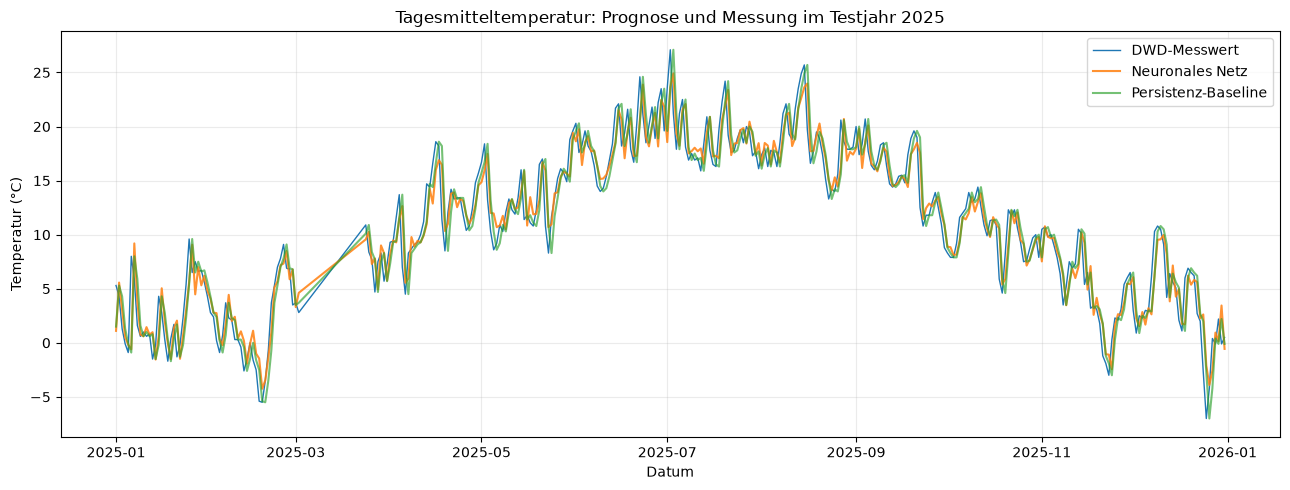

In [9]:
import matplotlib.pyplot as plt

test_ergebnisse = test_daten[["datum", zielspalte]].copy()
test_ergebnisse["ki_prognose_c"] = ki_prognose
test_ergebnisse["persistenz_c"] = persistenz_prognose

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    test_ergebnisse["datum"],
    test_ergebnisse[zielspalte],
    label="DWD-Messwert",
    linewidth=1,
)
ax.plot(
    test_ergebnisse["datum"],
    test_ergebnisse["ki_prognose_c"],
    label="Neuronales Netz",
    alpha=0.85,
)
ax.plot(
    test_ergebnisse["datum"],
    test_ergebnisse["persistenz_c"],
    label="Persistenz-Baseline",
    alpha=0.65,
)
ax.set_title("Tagesmitteltemperatur: Prognose und Messung im Testjahr 2025")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Schritt 5: Nächsten Tag prognostizieren

Die Testbewertung bleibt unverändert: Sie stammt aus dem Modell, das 2025 nicht gesehen hat. Für die aktuelle Ein-Tages-Prognose trainieren wir ein neues Modell mit allen verfügbaren Beispielen bis zum letzten DWD-Messtag. Als Eingabe dienen die fünf jüngsten aufeinanderfolgenden Tagesmitteltemperaturen und der Jahrestag des Prognosetags.

Falls einer dieser fünf Messwerte fehlt, bricht die Zelle bewusst mit einem Hinweis ab, statt fehlende Temperaturen stillschweigend zu schätzen.

In [10]:
from sklearn.base import clone

finales_modell = clone(temperatur_modell)
finales_modell.fit(modell_daten[feature_spalten], modell_daten[zielspalte])

letztes_messdatum = daten["datum"].max()
naechster_tag = letztes_messdatum + pd.Timedelta(days=1)
letzte_fuenf_daten = pd.date_range(end=letztes_messdatum, periods=5, freq="D")
temperaturreihe = daten.set_index("datum")["temp_avg_c"]
letzte_fuenf_temperaturen = temperaturreihe.reindex(letzte_fuenf_daten)

if letzte_fuenf_temperaturen.isna().any():
    raise ValueError(
        "Für die letzten fünf aufeinanderfolgenden Tage fehlen DWD-Temperaturen. "
        "Eine Prognose wird deshalb nicht berechnet."
    )

jahrestag = naechster_tag.day_of_year
if naechster_tag.is_leap_year and naechster_tag.month > 2:
    jahrestag -= 1

prognose_eingabe = {
    f"temp_avg_vortag_{lag}": float(letzte_fuenf_temperaturen.iloc[-lag])
    for lag in range(1, 6)
}
prognose_eingabe["tag_im_jahr"] = jahrestag
prognose_eingabe_df = pd.DataFrame([prognose_eingabe], columns=feature_spalten)
prognose_c = float(finales_modell.predict(prognose_eingabe_df)[0])

print("Verwendete letzte fünf Messwerte:")
display(
    letzte_fuenf_temperaturen.rename("Tagesmitteltemperatur (°C)")
    .rename_axis("Datum")
    .to_frame()
)
pd.DataFrame(
    {
        "Prognosedatum": [naechster_tag.date()],
        "Prognose Tagesmitteltemperatur (°C)": [round(prognose_c, 1)],
    }
)

Verwendete letzte fünf Messwerte:


,Tagesmitteltemperatur (°C)
Datum,
2026-10-28,8.8
2026-10-29,7.8
2026-10-30,7.6
2026-10-31,9.0
2026-11-01,8.2


,Prognosedatum,Prognose Tagesmitteltemperatur (°C)
0,2026-11-02,8.0


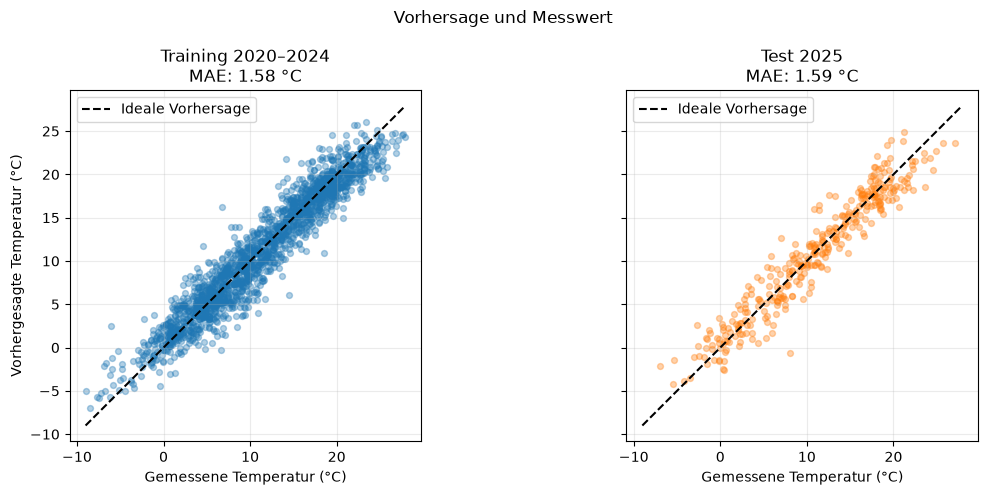

In [12]:
import matplotlib.pyplot as plt

untere_grenze = min(
    y_train.min(),
    y_test.min(),
    train_ki_prognose.min(),
    ki_prognose.min(),
)
obere_grenze = max(
    y_train.max(),
    y_test.max(),
    train_ki_prognose.max(),
    ki_prognose.max(),
)

fig, achsen = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
vergleichsgruppen = [
    (
        achsen[0],
        y_train,
        train_ki_prognose,
        "Training 2020–2024",
        metriken.loc["Training 2020–2024", "MAE_C"],
        "tab:blue",
    ),
    (
        achsen[1],
        y_test,
        ki_prognose,
        "Test 2025",
        metriken.loc["Test 2025", "MAE_C"],
        "tab:orange",
    ),
]

for ax, messwerte, vorhersagen, titel, mae, farbe in vergleichsgruppen:
    ax.scatter(messwerte, vorhersagen, alpha=0.35, s=18, color=farbe)
    ax.plot(
        [untere_grenze, obere_grenze],
        [untere_grenze, obere_grenze],
        "k--",
        label="Ideale Vorhersage",
    )
    ax.set_title(f"{titel}\nMAE: {mae:.2f} °C")
    ax.set_xlabel("Gemessene Temperatur (°C)")
    ax.grid(alpha=0.25)
    ax.legend()
    ax.set_aspect("equal", adjustable="box")

achsen[0].set_ylabel("Vorhergesagte Temperatur (°C)")
fig.suptitle("Vorhersage und Messwert")
fig.tight_layout()
plt.show()

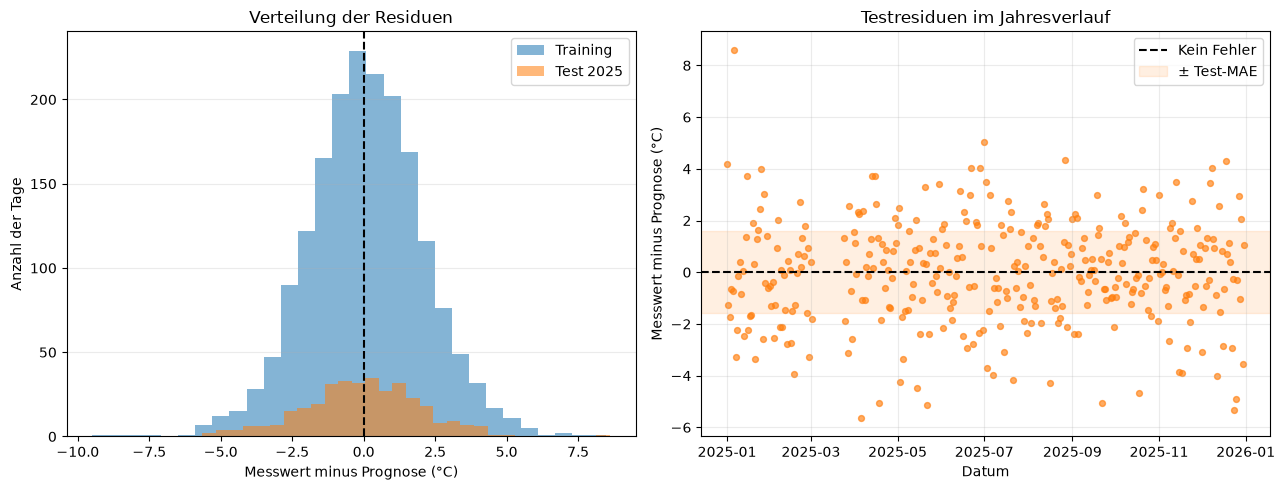

Mittleres Testresiduum: -0.03 °C


In [13]:
residuen_train = y_train.to_numpy() - train_ki_prognose
residuen_test = y_test.to_numpy() - ki_prognose

fig, achsen = plt.subplots(1, 2, figsize=(13, 5))
achsen[0].hist(residuen_train, bins=30, alpha=0.55, label="Training", color="tab:blue")
achsen[0].hist(residuen_test, bins=30, alpha=0.55, label="Test 2025", color="tab:orange")
achsen[0].axvline(0, color="black", linestyle="--")
achsen[0].set_title("Verteilung der Residuen")
achsen[0].set_xlabel("Messwert minus Prognose (°C)")
achsen[0].set_ylabel("Anzahl der Tage")
achsen[0].legend()
achsen[0].grid(axis="y", alpha=0.25)

achsen[1].scatter(test_daten["datum"], residuen_test, s=18, alpha=0.65, color="tab:orange")
achsen[1].axhline(0, color="black", linestyle="--", label="Kein Fehler")
achsen[1].axhspan(
    -metriken.loc["Test 2025", "MAE_C"],
    metriken.loc["Test 2025", "MAE_C"],
    alpha=0.12,
    color="tab:orange",
    label="± Test-MAE",
)
achsen[1].set_title("Testresiduen im Jahresverlauf")
achsen[1].set_xlabel("Datum")
achsen[1].set_ylabel("Messwert minus Prognose (°C)")
achsen[1].legend()
achsen[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()
print(f"Mittleres Testresiduum: {residuen_test.mean():.2f} °C")

## Fazit zur Modellgüte

- **Kein deutlicher Hinweis auf Overfitting:** MAE und R² sind im Training (1,585 °C; 0,920) und Test (1,589 °C; 0,919) sehr ähnlich.
- **Besser als die einfache Baseline:** Der Test-MAE des Netzes ist rund 9,7 % kleiner als „morgen wie gestern“ (1,589 °C gegenüber 1,760 °C).
- **Kaum mittlere Verzerrung:** Das mittlere Testresiduum beträgt −0,03 °C. Einzelne Tage weichen trotzdem deutlich ab.
- **Testgrenze:** 2025 ist nur ein einzelnes Testjahr. Für eine stabilere Einschätzung sollte man mehrere Jahre nacheinander als Testzeiträume prüfen.

Die Grafiken und Kennzahlen bewerten eine rollierende Ein-Tages-Prognose: Für jeden Testtag sind die tatsächlich gemessenen Temperaturen der fünf vorangegangenen Tage als Eingabe verfügbar.